# 02 – Graph neural network for xG (hand-rolled message passing in PyTorch)

**Input:** `shot_table.csv` and `player_table.csv` from `01_data_processing.ipynb`.

**What this notebook does**
1. Loads the two tables and checks them.
2. Turns each shot into a small graph: players are nodes, edges follow the *region rule*
   (shooter-centred half-discs + the cone to the two posts).
3. Implements message passing, four aggregators (sum / mean / max / attention) and several readouts from scratch.
4. Compares edge rules, number of rounds, readouts, aggregators and region radii on the **validation** set.
5. Evaluates the chosen model once on the **test** set against the set model (0 rounds) and StatsBomb xG.

**Why hand-rolled, not PyTorch Geometric?** It removes an install risk on laptops, makes the maths explicit
(useful for the reflection), and batching is just concatenation with an index offset.
A set model is the special case *0 message-passing rounds*, so both models share one code path
and the comparison is fair by construction (same features, same split, same training loop).

**AI note:** this code was written with AI assistance (see the brief's AI policy: allowed in the supplement only).

In [1]:
import json, time, copy, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Polygon
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

warnings.filterwarnings("ignore", category=UserWarning)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

torch 1.13.1+cu117 | device: cpu


## 0. Settings

* `MODE`: `"smoke"` (tiny, checks the code runs), `"fast"` (1 seed, short training), `"full"` (3 seeds, longer).
  Start with `smoke`, then `fast`, and use `full` for the final numbers.
* If the processed folder is not found automatically, set `PROC_DIR` by hand.
* Column names are assumptions taken from the data-processing notebook; the next cells print what was found
  and stop with a clear message if something does not match. Fix the names here.

In [2]:
MODE = "fast"          # "smoke" | "fast" | "full"
PROC_DIR = None        # e.g. r"C:/.../Data Science Toolbox/Group Sprint 2/data/processed"

MODES = {
    "smoke": dict(seeds=[0],       epochs=2,  max_train=3000),
    "fast":  dict(seeds=[0],       epochs=15, max_train=None),
    "full":  dict(seeds=[0, 1, 2], epochs=30, max_train=None),
}
SEEDS, MAX_EPOCHS, MAX_TRAIN = MODES[MODE]["seeds"], MODES[MODE]["epochs"], MODES[MODE]["max_train"]
PATIENCE = 5

# --- column names -------------------------------------------------------------------------
ID, MATCH, SPLIT = "shot_id", "match_id", "split"
BENCH = "statsbomb_xg"                       # evaluation only, never an input
P_X, P_Y = "x", "y"                          # RAW pitch coordinates in yards (player table)
P_TEAMMATE, P_KEEPER, P_SHOOTER = "teammate", "is_keeper", "is_shooter"

# Model-input columns. Leave None to read them from feature_columns.json.
PLAYER_FEATURES = None
SHOT_FEATURES = None
# Optional feature ablation, e.g. ["in_shot_triangle", "dist_to_shot_line_z"] to remove the engineered
# 'blocker' features and see whether the graph can learn blocking from raw geometry alone.
EXCLUDE_NODE_FEATURES = []

# Pitch geometry (StatsBomb: 120 x 80, everyone attacks towards x = 120)
GOAL_X, POST_L, POST_R = 120.0, 36.0, 44.0

In [3]:
def find_processed_dir():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        for cand in (p / "data" / "processed", p / "Group Sprint 2" / "data" / "processed"):
            if (cand / "shot_table.csv").exists():
                return cand
    raise FileNotFoundError(
        "Could not find data/processed/shot_table.csv. Make sure the outputs from "
        "01_data_processing.ipynb (shot_table.csv, player_table.csv and feature_columns.json) "
        "are in the same project's data/processed folder, or set PROC_DIR in the settings cell."
    )

PROC = Path(PROC_DIR) if PROC_DIR else find_processed_dir()
print("Using:", PROC)

shot_df = pd.read_csv(PROC / "shot_table.csv")
player_df = pd.read_csv(PROC / "player_table.csv")
print("shots:", shot_df.shape, "| players:", player_df.shape)

TARGET = next((c for c in ["is_goal", "goal"] if c in shot_df.columns), None)
assert TARGET, "No target column ('is_goal' or 'goal') in shot table"
assert set(shot_df[TARGET].unique()) <= {0, 1, True, False}, "target must be binary"

Using: /home/jovyan/Data Science Toolbox/Group Sprint 2/data/processed
shots: (53508, 43) | players: (737954, 27)


## 1. Load, resolve feature lists and check the tables

Why: the graph builder needs (a) the **raw** coordinates in yards to apply the 7-yard / 3–4-yard region and the
cone, and (b) the **scaled** model-input columns to feed the network. Keeping the two apart stops the region
being computed on standardised numbers by accident.

In [4]:
LEAK = {"statsbomb_xg", "outcome", "end_x", "end_y", "end_z", "is_goal", "goal", TARGET}

def pick_list(fc, kind):
    """Find the list of model-input columns for 'shot' or 'player' inside feature_columns.json."""
    if not isinstance(fc, dict):
        return None
    for k in [f"{kind}_features", f"{kind}_cols", f"{kind}_columns", f"{kind}_inputs",
              f"{kind}_model_cols", f"{kind}_model_columns", kind]:
        if isinstance(fc.get(k), list):
            return list(fc[k])
    for v in fc.values():                       # nested, e.g. {"model_inputs": {"shot": [...]}}
        if isinstance(v, dict):
            r = pick_list(v, kind)
            if r:
                return r
    bad = ("raw", "meta", "key", "drop", "bench", "target", "label")
    hits = [k for k, v in fc.items() if isinstance(v, list) and kind in k.lower()
            and not any(b in k.lower() for b in bad)]
    if hits:
        print(f"  [{kind}] combining keys: {hits}")
        return [c for k in hits for c in fc[k]]
    return None

fc_path = PROC / "feature_columns.json"
fc = json.loads(fc_path.read_text()) if fc_path.exists() else None
if fc is not None:
    print("feature_columns.json keys:", list(fc.keys()) if isinstance(fc, dict) else type(fc))

if PLAYER_FEATURES is None:
    PLAYER_FEATURES = pick_list(fc, "player")
if SHOT_FEATURES is None:
    SHOT_FEATURES = pick_list(fc, "shot")
if not PLAYER_FEATURES or not SHOT_FEATURES:
    raise ValueError("Could not read feature lists from feature_columns.json. "
                     "Set PLAYER_FEATURES and SHOT_FEATURES by hand in the settings cell.")

PLAYER_FEATURES = [c for c in PLAYER_FEATURES if c not in EXCLUDE_NODE_FEATURES]

for name, cols, df in [("player", PLAYER_FEATURES, player_df), ("shot", SHOT_FEATURES, shot_df)]:
    missing = [c for c in cols if c not in df.columns]
    assert not missing, f"{name} features not in table: {missing}"
    leaked = [c for c in cols if c in LEAK]
    assert not leaked, f"LEAKAGE: {leaked} must not be a {name} input"
    assert not df[cols].isna().any().any(), f"NaNs in {name} features"
print(f"node features: {len(PLAYER_FEATURES)} | shot features: {len(SHOT_FEATURES)}")
print("node features:", PLAYER_FEATURES)
print("shot features:", SHOT_FEATURES)

# required raw geometry columns
for c in [ID, P_X, P_Y, P_TEAMMATE, P_KEEPER, P_SHOOTER]:
    assert c in player_df.columns, f"player table missing '{c}'"
for c in [ID, MATCH, SPLIT]:
    assert c in shot_df.columns, f"shot table missing '{c}'"
assert player_df[P_X].between(-5, 125).all() and player_df[P_Y].between(-5, 85).all(), \
    f"'{P_X}','{P_Y}' do not look like raw yards - are they the scaled columns?"

feature_columns.json keys: ['id_cols', 'meta_cols', 'target', 'benchmark_only', 'shot_features', 'player_features', 'raw_shot_geometry', 'raw_player_geometry', 'optional_player_columns']
node features: 14 | shot features: 29
node features: ['x_z', 'y_z', 'dx_z', 'dy_z', 'dist_goal_z', 'angle_goal_z', 'dist_shooter_z', 'dist_to_shot_line_z', 'angle_shooter_sin', 'angle_shooter_cos', 'teammate', 'is_keeper', 'is_shooter', 'in_shot_triangle']
shot features: ['location_x_z', 'location_y_z', 'dist_goal_z', 'angle_goal_z', 'first_time', 'under_pressure', 'shot_type_Free_Kick', 'shot_type_Open_Play', 'shot_type_Other', 'body_part_Head', 'body_part_Left_Foot', 'body_part_Other', 'body_part_Right_Foot', 'technique_Backheel', 'technique_Diving_Header', 'technique_Half_Volley', 'technique_Lob', 'technique_Normal', 'technique_Overhead_Kick', 'technique_Volley', 'play_pattern_From_Corner', 'play_pattern_From_Counter', 'play_pattern_From_Free_Kick', 'play_pattern_From_Goal_Kick', 'play_pattern_From_

In [5]:
# --- splits: made by match in 01_data_processing, we only read them ---------------------------
shot_df[SPLIT] = (shot_df[SPLIT].astype(str).str.lower().str.strip()
                  .replace({"validation": "val", "valid": "val"}))
assert {"train", "val", "test"} <= set(shot_df[SPLIT]), f"unexpected splits: {shot_df[SPLIT].unique()}"
m_split = shot_df.groupby(MATCH)[SPLIT].nunique()
assert (m_split == 1).all(), "a match appears in more than one split (leakage)"
print(shot_df[SPLIT].value_counts().to_dict(), "| goal rate by split:",
      shot_df.groupby(SPLIT)[TARGET].mean().round(3).to_dict())

# --- align player rows to shot order ------------------------------------------------------------
shot_index = pd.Series(np.arange(len(shot_df)), index=shot_df[ID].values)
player_df["_s"] = player_df[ID].map(shot_index)
assert player_df["_s"].notna().all(), "players belong to shots that are not in the shot table"
player_df = player_df.sort_values("_s", kind="stable").reset_index(drop=True)
S = len(shot_df)
ncount0 = np.bincount(player_df["_s"].astype(int), minlength=S)
assert (ncount0 > 0).all(), "some shots have no player rows"
NODE_PTR0 = np.concatenate([[0], np.cumsum(ncount0)])

shooter_per_shot = player_df.groupby("_s")[P_SHOOTER].sum()
assert (shooter_per_shot == 1).all(), "every shot needs exactly one shooter row"
opp_keepers = ((player_df[P_KEEPER] == 1) & (player_df[P_TEAMMATE] == 0)).groupby(player_df["_s"]).sum()
print(f"nodes per graph: mean {ncount0.mean():.1f}, min {ncount0.min()}, max {ncount0.max()} | "
      f"shots without an opposition keeper: {(opp_keepers == 0).sum()}")

# --- global arrays (CPU) -----------------------------------------------------------------------
X_NODE = torch.tensor(player_df[PLAYER_FEATURES].astype("float32").values)
POS = torch.tensor(player_df[[P_X, P_Y]].astype("float32").values)
TEAM = player_df[P_TEAMMATE].astype(int).values
KEEPER = player_df[P_KEEPER].astype(int).values
SHOOTER = player_df[P_SHOOTER].astype(int).values
U = torch.tensor(shot_df[SHOT_FEATURES].astype("float32").values)
Y = torch.tensor(shot_df[TARGET].astype("float32").values)
MATCH_IDS = shot_df[MATCH].values
SHOT_IDS = shot_df[ID].values
BENCH_P = shot_df[BENCH].values if BENCH in shot_df.columns else None

rng0 = np.random.default_rng(0)
IDX = {s: np.flatnonzero((shot_df[SPLIT] == s).values) for s in ["train", "val", "test"]}
if MAX_TRAIN and len(IDX["train"]) > MAX_TRAIN:                # smoke mode only
    IDX["train"] = rng0.choice(IDX["train"], MAX_TRAIN, replace=False)
print({k: len(v) for k, v in IDX.items()})

{'train': 37431, 'test': 8075, 'val': 8002} | goal rate by split: {'test': 0.099, 'train': 0.103, 'val': 0.109}
nodes per graph: mean 13.8, min 3, max 22 | shots without an opposition keeper: 0
{'train': 37431, 'val': 8002, 'test': 8075}


## 2. Graph construction: the region rule

**Nodes.** Every visible player and the shooter (all rows of the player table for that shot).

**Region** (your design), all in raw yards with the shooter at `(sx, sy)` attacking towards `x = 120`:
* *vertical split*: the line `x = sx` through the shooter;
* *in front* (`x > sx`): half-disc of radius `R_FRONT` (default 7 yd);
* *behind* (`x <= sx`): half-disc of radius `R_BACK` (default 4 yd; 3 is tried in the radius sweep);
* *cone*: the triangle shooter → left post `(120, 36)` → right post `(120, 44)`.

A player is *in the region* if they are in any of the three. The opposition keeper is always linked to the
shooter, even if outside the region (on wide shots the keeper can fall outside the cone and losing them would hurt).

**Edge rules compared** (edges are directed both ways):
| name | edges |
|---|---|
| `none` | no edges, with 0 rounds this is the **set model** |
| `star` (A) | shooter ↔ region players (+ opposition keeper) |
| `star_keeper` (B) | A, plus opposition keeper ↔ every region player |
| `region_full` (C) | all pairs among {shooter, region players, opposition keeper} |
| `full` (D) | all pairs of all players (no region) |

**Edge features** for an edge from sender *i* to receiver *j*: distance, `(x_i - x_j)`, `(y_i - y_j)` (all `/20`,
a fixed constant, not a data statistic) and a same-team flag. They are computed from raw positions at batch time,
so nothing big is stored per edge.

**Players outside the region** stay as nodes by default (they still reach the readout, like in a set model).
`drop_outside=True` removes them, which is one of the experiments.

In [6]:
def _cross(ax, ay, bx, by, px, py):
    return (bx - ax) * (py - ay) - (by - ay) * (px - ax)

def in_shot_cone(px, py, sx, sy):
    """Inside (or on) the triangle shooter -> left post -> right post. Degenerate triangles give False."""
    d1 = _cross(sx, sy, GOAL_X, POST_L, px, py)
    d2 = _cross(GOAL_X, POST_L, GOAL_X, POST_R, px, py)
    d3 = _cross(GOAL_X, POST_R, sx, sy, px, py)
    has_neg = (d1 < 0) | (d2 < 0) | (d3 < 0)
    has_pos = (d1 > 0) | (d2 > 0) | (d3 > 0)
    return ~(has_neg & has_pos)

def region_mask(px, py, sx, sy, r_front, r_back):
    dx, dy = px - sx, py - sy
    d = np.hypot(dx, dy)
    discs = np.where(dx > 0, d <= r_front, d <= r_back)
    return discs | in_shot_cone(px, py, sx, sy)

def _pairs(nodes):
    nodes = np.asarray(nodes)
    a, b = np.meshgrid(nodes, nodes, indexing="ij")
    m = a != b
    return a[m].astype(np.int16), b[m].astype(np.int16)

_EMPTY = np.zeros(0, dtype=np.int16)
REGION_RULES = ("star", "star_keeper", "region_full")

def build_edges(rule, px, py, team, keeper, shooter, r_front, r_back):
    """Directed edge lists (src, dst) as local node indices for ONE shot."""
    n = len(px)
    if rule == "none":
        return _EMPTY, _EMPTY
    if rule == "full":
        return _pairs(np.arange(n))
    s = int(np.flatnonzero(shooter)[0])
    keepers = np.flatnonzero((keeper == 1) & (team == 0))
    inreg = region_mask(px, py, px[s], py[s], r_front, r_back)
    inreg[s] = False
    members = np.flatnonzero(inreg)
    members_k = np.setdiff1d(np.union1d(members, keepers), [s])    # region + opposition keeper
    if rule == "star":
        src = np.concatenate([np.full(len(members_k), s), members_k])
        dst = np.concatenate([members_k, np.full(len(members_k), s)])
        return src.astype(np.int16), dst.astype(np.int16)
    if rule == "star_keeper":
        src = [np.full(len(members_k), s), members_k]
        dst = [members_k, np.full(len(members_k), s)]
        for k in keepers:
            others = members_k[members_k != k]
            src += [np.full(len(others), k), others]
            dst += [others, np.full(len(others), k)]
        return np.concatenate(src).astype(np.int16), np.concatenate(dst).astype(np.int16)
    if rule == "region_full":
        return _pairs(np.concatenate([[s], members_k]))
    raise ValueError(rule)

In [7]:
def _ranges(starts, counts):
    """Concatenate arange(start, start+count) for many (start, count) pairs, vectorised."""
    total = int(counts.sum())
    offs = np.repeat(np.cumsum(counts) - counts, counts)
    return np.repeat(starts, counts) + (np.arange(total) - offs)

class Batch:
    """Plain container: one big disconnected graph made of several shots."""
    def to(self, device):
        for k, v in self.__dict__.items():
            if torch.is_tensor(v):
                setattr(self, k, v.to(device))
        return self

class GraphStore:
    """All shots for one edge rule, stored flat, with a vectorised batcher (no padding needed)."""
    def __init__(self, node_rows, ncount, src, dst, ecount):
        rows = torch.from_numpy(node_rows)
        self.x, self.pos = X_NODE[rows], POS[rows]
        self.team = torch.from_numpy(TEAM[node_rows])
        self.shooter = torch.from_numpy(SHOOTER[node_rows]).bool()
        self.ncount, self.ecount = ncount, ecount
        self.nptr = np.concatenate([[0], np.cumsum(ncount)])
        self.eptr = np.concatenate([[0], np.cumsum(ecount)])
        self.src, self.dst = src, dst
        self.mean_edges = float(ecount.mean())

    def batch(self, idx):
        idx = np.asarray(idx)
        nc, ec = self.ncount[idx], self.ecount[idx]
        nrows = torch.from_numpy(_ranges(self.nptr[idx], nc))
        erows = _ranges(self.eptr[idx], ec)
        noff = np.cumsum(nc) - nc
        src = torch.from_numpy(self.src[erows].astype(np.int64) + np.repeat(noff, ec))
        dst = torch.from_numpy(self.dst[erows].astype(np.int64) + np.repeat(noff, ec))
        b = Batch()
        b.x, pos, team = self.x[nrows], self.pos[nrows], self.team[nrows]
        b.is_shooter = self.shooter[nrows]
        b.node_graph = torch.from_numpy(np.repeat(np.arange(len(idx)), nc))
        b.src, b.dst, b.n_graphs = src, dst, len(idx)
        d = pos[src] - pos[dst]
        same = (team[src] == team[dst]).float().unsqueeze(1)
        b.edge_attr = torch.cat([d.norm(dim=1, keepdim=True) / 20, d / 20, same], 1)
        b.u, b.y = U[idx], Y[idx]
        return b

STORE_CACHE = {}

def build_store(rule, r_front=7.0, r_back=4.0, drop_outside=False):
    key = (rule, r_front, r_back, drop_outside and rule in REGION_RULES)
    if key in STORE_CACHE:
        return STORE_CACHE[key]
    t0 = time.time()
    node_rows, ncount, ecount, srcs, dsts = [], np.zeros(S, int), np.zeros(S, int), [], []
    for i in range(S):
        a, b = NODE_PTR0[i], NODE_PTR0[i + 1]
        px, py = POS[a:b, 0].numpy(), POS[a:b, 1].numpy()
        team, kp, sh = TEAM[a:b], KEEPER[a:b], SHOOTER[a:b]
        if key[3]:                                   # drop players outside the region
            s = int(np.flatnonzero(sh)[0])
            keep = region_mask(px, py, px[s], py[s], r_front, r_back) | (sh == 1) | ((kp == 1) & (team == 0))
            sub = np.flatnonzero(keep)
        else:
            sub = np.arange(b - a)
        es, ed = build_edges(rule, px[sub], py[sub], team[sub], kp[sub], sh[sub], r_front, r_back)
        node_rows.append(a + sub); ncount[i] = len(sub)
        srcs.append(es); dsts.append(ed); ecount[i] = len(es)
    store = GraphStore(np.concatenate(node_rows), ncount, np.concatenate(srcs), np.concatenate(dsts), ecount)
    STORE_CACHE[key] = store
    print(f"  built graphs for {key}: {store.mean_edges:.1f} directed edges/graph, "
          f"{ncount.mean():.1f} nodes/graph ({time.time() - t0:.0f}s)")
    return store

### Look at the region and the edges (sanity check for the report)
Pick a shot and draw each rule. Check that the half-discs, the cone and the keeper link look right.

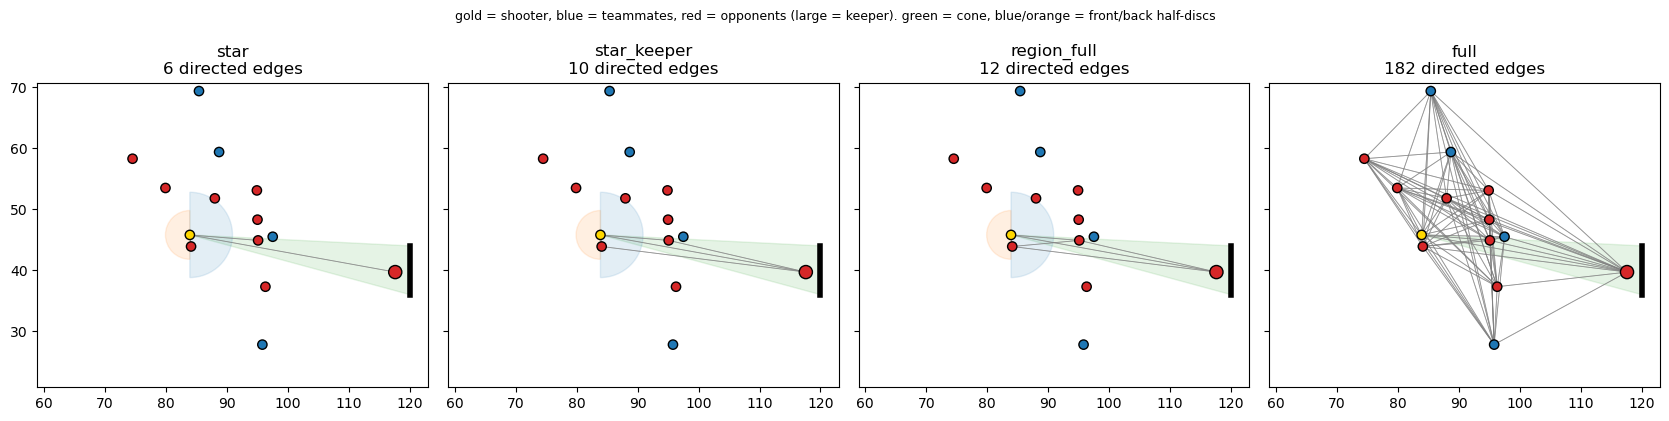

In [8]:
def plot_shot_graph(shot_i, rules=("star", "star_keeper", "region_full", "full"), r_front=7.0, r_back=4.0):
    a, b = NODE_PTR0[shot_i], NODE_PTR0[shot_i + 1]
    px, py = POS[a:b, 0].numpy(), POS[a:b, 1].numpy()
    team, kp, sh = TEAM[a:b], KEEPER[a:b], SHOOTER[a:b]
    s = int(np.flatnonzero(sh)[0]); sx, sy = px[s], py[s]
    fig, axes = plt.subplots(1, len(rules), figsize=(4.2 * len(rules), 4.4), sharex=True, sharey=True)
    for ax, rule in zip(np.atleast_1d(axes), rules):
        ax.add_patch(Polygon([[sx, sy], [GOAL_X, POST_L], [GOAL_X, POST_R]], alpha=0.12, color="tab:green"))
        if rule in REGION_RULES:
            ax.add_patch(Wedge((sx, sy), r_front, -90, 90, alpha=0.12, color="tab:blue"))
            ax.add_patch(Wedge((sx, sy), r_back, 90, 270, alpha=0.12, color="tab:orange"))
        es, ed = build_edges(rule, px, py, team, kp, sh, r_front, r_back)
        for u_, v_ in zip(es, ed):
            ax.plot([px[u_], px[v_]], [py[u_], py[v_]], color="grey", lw=0.6, alpha=0.6, zorder=1)
        col = np.where(sh == 1, "gold", np.where(team == 1, "tab:blue", "tab:red"))
        ax.scatter(px, py, c=col, s=np.where(kp == 1, 90, 45), edgecolor="k", zorder=3)
        ax.plot([GOAL_X, GOAL_X], [POST_L, POST_R], color="k", lw=4)
        ax.set_title(f"{rule}\n{len(es)} directed edges"); ax.set_aspect("equal")
    ax.set_xlim(sx - 25, 123); ax.set_ylim(sy - 25, sy + 25)
    fig.suptitle("gold = shooter, blue = teammates, red = opponents (large = keeper). "
                 "green = cone, blue/orange = front/back half-discs", fontsize=9)
    plt.tight_layout(); plt.show()

example = next(i for i in IDX["val"] if ncount0[i] >= 12)      # a shot with a reasonably full frame
plot_shot_graph(int(example))

## 3. The model

One **message-passing round** for node *i* with incoming edges *(j → i)*:

`m_ji = MLP_msg([h_i, h_j, e_ji])`  →  `a_i = AGGR_j m_ji`  →  `h_i ← LayerNorm(h_i + MLP_upd([h_i, a_i]))`

* `AGGR` is `sum`, `mean`, `max`, or `attn`, where `attn` weights each message by a softmax over the
  incoming edges of node *i* (a GAT-style attention; on a fully connected graph this is close to a transformer layer).
* Nodes with no incoming edges receive `a_i = 0`, so they are only updated from their own state.
* After `L` rounds a node has information from players up to `L` edges away.

**Readout** pools the node vectors into one vector per shot: `sum`, `mean`, `max`, `shooter` (the shooter node's
vector) or a combination such as `shooter+sum` (concatenated). The shot features `u` are then concatenated
and an MLP gives one logit. This is the same head for every model, including the set model.

**Set model = 0 rounds.** The node encoder is applied to each player independently and the readout pools them
(Deep Sets). Permutation invariance holds for the sum/mean/max readouts.

In [9]:
def scatter_sum(src, index, n):
    out = src.new_zeros((n,) + src.shape[1:])
    return out.index_add_(0, index, src)

def scatter_mean(src, index, n):
    cnt = torch.bincount(index, minlength=n).clamp(min=1).to(src.dtype).unsqueeze(1)
    return scatter_sum(src, index, n) / cnt

def scatter_max(src, index, n):
    out = src.new_zeros((n,) + src.shape[1:])
    return out.scatter_reduce(0, index.unsqueeze(1).expand_as(src), src, reduce="amax", include_self=False)

def segment_softmax(score, index, n):
    mx = score.new_full((n,), float("-inf")).scatter_reduce(0, index, score, reduce="amax", include_self=True)
    ex = torch.exp(score - mx[index])
    return ex / (scatter_sum(ex, index, n)[index] + 1e-12)

class MPLayer(nn.Module):
    def __init__(self, h, e_dim, aggr="sum"):
        super().__init__()
        self.aggr = aggr
        self.msg = nn.Sequential(nn.Linear(2 * h + e_dim, h), nn.ReLU(), nn.Linear(h, h))
        self.upd = nn.Sequential(nn.Linear(2 * h, h), nn.ReLU(), nn.Linear(h, h))
        self.norm = nn.LayerNorm(h)
        if aggr == "attn":
            self.score = nn.Linear(h, 1)

    def forward(self, h, src, dst, e):
        n = h.size(0)
        if src.numel() == 0:
            agg = torch.zeros_like(h)
        else:
            m = self.msg(torch.cat([h[dst], h[src], e], 1))
            if self.aggr == "sum":
                agg = scatter_sum(m, dst, n)
            elif self.aggr == "mean":
                agg = scatter_mean(m, dst, n)
            elif self.aggr == "max":
                agg = scatter_max(m, dst, n)
            elif self.aggr == "attn":
                alpha = segment_softmax(self.score(m).squeeze(1), dst, n)
                agg = scatter_sum(alpha.unsqueeze(1) * m, dst, n)
            else:
                raise ValueError(self.aggr)
        return self.norm(h + self.upd(torch.cat([h, agg], 1)))

class GraphXG(nn.Module):
    def __init__(self, node_dim, shot_dim, edge_dim=4, hidden=64, rounds=2, aggr="sum",
                 readout="shooter+sum", dropout=0.1):
        super().__init__()
        self.parts = readout.split("+")
        assert all(p in ("sum", "mean", "max", "shooter") for p in self.parts), readout
        self.enc = nn.Sequential(nn.Linear(node_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
        self.layers = nn.ModuleList([MPLayer(hidden, edge_dim, aggr) for _ in range(rounds)])
        self.head = nn.Sequential(
            nn.Linear(hidden * len(self.parts) + shot_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, 1))

    def pool(self, h, b, part):
        if part == "sum":
            return scatter_sum(h, b.node_graph, b.n_graphs)
        if part == "mean":
            return scatter_mean(h, b.node_graph, b.n_graphs)
        if part == "max":
            return scatter_max(h, b.node_graph, b.n_graphs)
        sel = h[b.is_shooter]
        assert sel.size(0) == b.n_graphs, "each graph must contain exactly one shooter node"
        return sel

    def forward(self, b):
        h = self.enc(b.x)
        for layer in self.layers:
            h = layer(h, b.src, b.dst, b.edge_attr)
        g = torch.cat([self.pool(h, b, p) for p in self.parts], 1)
        return self.head(torch.cat([g, b.u], 1)).squeeze(1)

### Quick correctness tests
* permutation invariance: shuffling the players inside a shot must not change the output;
* the batcher must give the same prediction whether a shot is alone or in a batch.

In [10]:
def _check_model():
    store = build_store("region_full")
    torch.manual_seed(0)
    idx = IDX["val"][:8]
    for aggr in ["sum", "mean", "max", "attn"]:
        model = GraphXG(X_NODE.shape[1], U.shape[1], rounds=2, aggr=aggr, readout="shooter+sum").eval()
        with torch.no_grad():
            full = model(store.batch(idx))
            alone = torch.cat([model(store.batch(idx[i:i + 1])) for i in range(len(idx))])
            # permute node order inside each graph and relabel the edges consistently
            b = store.batch(idx)
            perm = torch.cat([torch.randperm(int(c)) + o for c, o in
                              zip(store.ncount[idx], np.cumsum(store.ncount[idx]) - store.ncount[idx])])
            inv = torch.empty_like(perm); inv[perm] = torch.arange(len(perm))
            b2 = Batch(); b2.__dict__.update(b.__dict__)
            b2.x, b2.is_shooter, b2.node_graph = b.x[perm], b.is_shooter[perm], b.node_graph[perm]
            b2.src, b2.dst = inv[b.src], inv[b.dst]
            permuted = model(b2)
        assert torch.allclose(full, alone, atol=1e-4), f"{aggr}: batch vs single mismatch"
        assert torch.allclose(full, permuted, atol=1e-4), f"{aggr}: not permutation invariant"
    print("OK: batching is consistent and the model is permutation invariant (sum/mean/max/attn).")

_check_model()

  built graphs for ('region_full', 7.0, 4.0, False): 22.9 directed edges/graph, 13.8 nodes/graph (11s)
OK: batching is consistent and the model is permutation invariant (sum/mean/max/attn).


## 4. Training and evaluation

* Loss: binary cross-entropy on the **unweighted** data. No resampling, because it would break calibration, which is what makes an xG model useful.
* Optimiser: AdamW, gradient clipping, early stopping on **validation** log loss (best weights restored).
* Metrics: log loss (primary, a proper scoring rule), Brier score, ROC-AUC.
* We also record time per epoch, graphs/second and edges per graph. These are the numbers for the computational-performance / 1000x scaling section.

In [11]:
def metrics(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return dict(logloss=log_loss(y, p, labels=[0, 1]), brier=brier_score_loss(y, p), auc=roc_auc_score(y, p))

@torch.no_grad()
def predict(model, store, idx, bs=1024):
    model.eval()
    out = [torch.sigmoid(model(store.batch(idx[i:i + bs]).to(DEVICE))).cpu() for i in range(0, len(idx), bs)]
    return torch.cat(out).numpy()

def train_model(cfg, seed, verbose=False):
    store = build_store(cfg["rule"], cfg["r_front"], cfg["r_back"], cfg["drop_outside"])
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = GraphXG(X_NODE.shape[1], U.shape[1], hidden=cfg["hidden"], rounds=cfg["rounds"], aggr=cfg["aggr"],
                    readout=cfg["readout"], dropout=cfg["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    lossf = nn.BCEWithLogitsLoss()
    y_val = Y[IDX["val"]].numpy()
    best, best_state, best_ep, bad, ep_times = np.inf, None, 0, 0, []
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); t0 = time.time()
        order = rng.permutation(IDX["train"])
        for i in range(0, len(order), cfg["batch_size"]):
            b = store.batch(order[i:i + cfg["batch_size"]]).to(DEVICE)
            opt.zero_grad()
            loss = lossf(model(b), b.y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        ep_times.append(time.time() - t0)
        val_ll = metrics(y_val, predict(model, store, IDX["val"]))["logloss"]
        if verbose:
            print(f"    epoch {ep:2d}  val logloss {val_ll:.4f}  ({ep_times[-1]:.1f}s)")
        if val_ll < best - 1e-5:
            best, best_state, best_ep, bad = val_ll, copy.deepcopy(model.state_dict()), ep, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    preds = {s: predict(model, store, IDX[s]) for s in ["val", "test"]}
    row = dict(best_epoch=best_ep, epochs_run=ep, epoch_time_s=float(np.mean(ep_times)),
               graphs_per_s=len(IDX["train"]) / float(np.mean(ep_times)), edges_per_graph=store.mean_edges,
               n_params=sum(p.numel() for p in model.parameters()))
    for s in ["val", "test"]:
        for k, v in metrics(Y[IDX[s]].numpy(), preds[s]).items():
            row[f"{s}_{k}"] = v
    return row, preds

## 5. Experiments (greedy, sequential, selected on the validation set only)

Order: edge rule → number of rounds → readout → aggregator → region radii.
Each step starts from the best configuration so far. This is cheaper than a full grid but is greedy: interactions
between settings (e.g. attention only helping with more rounds) can be missed. Say so in the report.
Test-set numbers are recorded in the table but **never used for selection**.

In [12]:
BASE = dict(rule="region_full", rounds=2, aggr="sum", readout="shooter+sum", hidden=64, dropout=0.1,
            lr=1e-3, wd=1e-4, batch_size=256, r_front=7.0, r_back=4.0, drop_outside=False)
CONFIGS, RESULTS, PREDS, TAGS = {}, [], {}, {}
OUT_RESULTS = PROC / "graph_results.csv"

def run_experiment(tag, named_overrides):
    # Register the full experiment before training. This also makes selection robust
    # if a previous run was interrupted and the cell is re-executed.
    TAGS.setdefault(tag, [])
    for name, ov in named_overrides.items():
        cfg = {**BASE, **ov}
        CONFIGS[name] = cfg
        if name not in TAGS[tag]:
            TAGS[tag].append(name)
        for seed in SEEDS:
            if any(r["name"] == name and r["seed"] == seed for r in RESULTS):
                continue
            # Identical configuration already trained under another name? Reuse it.
            twin = next((r for r in RESULTS
                         if r["seed"] == seed and CONFIGS.get(r["name"]) == cfg), None)
            if twin is not None:
                RESULTS.append({**twin, "experiment": tag, "name": name})
                PREDS[(name, seed)] = PREDS[(twin["name"], seed)]
                pd.DataFrame(RESULTS).to_csv(OUT_RESULTS, index=False)
                print(f"  {name:<28s} seed {seed}: same config as '{twin['name']}' -> reused")
                continue
            t0 = time.time()
            row, preds = train_model(cfg, seed)
            RESULTS.append(dict(experiment=tag, name=name, seed=seed, **{k: cfg[k] for k in
                                ["rule", "rounds", "aggr", "readout", "r_front", "r_back", "drop_outside"]}, **row))
            PREDS[(name, seed)] = preds
            pd.DataFrame(RESULTS).to_csv(OUT_RESULTS, index=False)
            print(f"  {name:<28s} seed {seed}: val logloss {row['val_logloss']:.4f} "
                  f"(epoch {row['best_epoch']}, {time.time() - t0:.0f}s)")
    return summarise(TAGS[tag])

def summarise(names=None):
    if not RESULTS:
        raise RuntimeError("No experiment results are available. Run the experiment cells in order, starting at Experiment 1.")
    df = pd.DataFrame(RESULTS)
    if names is not None:
        df = df[df["name"].isin(names)]
    if df.empty:
        raise RuntimeError("No results found for the requested experiment. Re-run the relevant experiment cell.")
    cols = ["val_logloss", "val_brier", "val_auc", "test_logloss", "epoch_time_s", "graphs_per_s", "edges_per_graph"]
    g = df.groupby("name", sort=False)[cols].agg(["mean", "std"] if len(SEEDS) > 1 else ["mean"])
    g.columns = ["_".join(c) for c in g.columns]
    return g.sort_values("val_logloss_mean")

def best_name(tag, exclude=(), only_rules=None):
    # Recover names from RESULTS if TAGS was lost/reset in an interrupted session.
    names = TAGS.get(tag, [])
    if not names:
        names = list(dict.fromkeys(r["name"] for r in RESULTS if r.get("experiment") == tag))
        TAGS[tag] = names
    if not names:
        raise RuntimeError(f"No completed results for {tag}. Run its experiment cell before selecting a model.")
    s = summarise(names)
    s = s[~s.index.isin(exclude)]
    if only_rules:
        s = s[[CONFIGS[n]["rule"] in only_rules for n in s.index]]
    if s.empty:
        raise RuntimeError(f"No eligible models remain when selecting the best configuration for {tag}.")
    return s.index[0]


In [13]:
# Experiment 1 - edge rule (2 rounds), with the set model (0 rounds) as the reference
E1 = {"set (0 rounds)": dict(rounds=0, rule="none"),
      "A star": dict(rule="star"),
      "B star+keeper": dict(rule="star_keeper"),
      "C region full": dict(rule="region_full"),
      "D all-to-all": dict(rule="full")}
print("Experiment 1: edge rules"); run_experiment("E1_rules", E1)

Experiment 1: edge rules
  built graphs for ('none', 7.0, 4.0, False): 0.0 directed edges/graph, 13.8 nodes/graph (1s)
  set (0 rounds)               seed 0: val logloss 0.2755 (epoch 14, 14s)
  built graphs for ('star', 7.0, 4.0, False): 7.9 directed edges/graph, 13.8 nodes/graph (9s)
  A star                       seed 0: val logloss 0.2755 (epoch 15, 69s)
  built graphs for ('star_keeper', 7.0, 4.0, False): 13.7 directed edges/graph, 13.8 nodes/graph (9s)
  B star+keeper                seed 0: val logloss 0.2783 (epoch 7, 65s)
  C region full                seed 0: val logloss 0.2756 (epoch 14, 87s)
  built graphs for ('full', 7.0, 4.0, False): 189.2 directed edges/graph, 13.8 nodes/graph (3s)
  D all-to-all                 seed 0: val logloss 0.2754 (epoch 15, 435s)


,val_logloss_mean,val_brier_mean,val_auc_mean,test_logloss_mean,epoch_time_s_mean,graphs_per_s_mean,edges_per_graph_mean
name,,,,,,,
D all-to-all,0.275411,0.079753,0.811592,0.257009,25.122292,1489.951649,189.214286
set (0 rounds),0.275470,0.079210,0.808082,0.258453,0.798109,46899.622557,0.000000
A star,0.275538,0.079480,0.810413,0.258476,3.726309,10045.059782,7.856171
C region full,0.275596,0.079517,0.807763,0.255152,5.282653,7085.644046,22.895492
B star+keeper,0.278275,0.080016,0.805695,0.255831,4.244772,8818.141104,13.712342


In [14]:
best_rule_name = best_name("E1_rules", exclude=["set (0 rounds)"])
print("best graph rule so far:", best_rule_name)
rule_best = CONFIGS[best_rule_name]["rule"]
E2 = {f"{rule_best}, {L} round{'s' if L != 1 else ''}": dict(rule=rule_best, rounds=L) for L in (1, 2, 3)}
print("Experiment 2: number of message-passing rounds"); run_experiment("E2_rounds", E2)

best graph rule so far: D all-to-all
Experiment 2: number of message-passing rounds
  full, 1 round                seed 0: val logloss 0.2745 (epoch 14, 242s)
  full, 2 rounds               seed 0: same config as 'D all-to-all' -> reused
  full, 3 rounds               seed 0: val logloss 0.2751 (epoch 15, 610s)


,val_logloss_mean,val_brier_mean,val_auc_mean,test_logloss_mean,epoch_time_s_mean,graphs_per_s_mean,edges_per_graph_mean
name,,,,,,,
"full, 1 round",0.274517,0.079293,0.810672,0.256917,13.743971,2723.448675,189.214286
"full, 3 rounds",0.275057,0.079503,0.809241,0.254835,36.144882,1035.582290,189.214286
"full, 2 rounds",0.275411,0.079753,0.811592,0.257009,25.122292,1489.951649,189.214286


In [15]:
best2 = best_name("E2_rounds")
b2 = CONFIGS[best2]
E3 = {f"readout {r}": dict(rule=b2["rule"], rounds=b2["rounds"], readout=r)
      for r in ["sum", "mean", "max", "shooter", "shooter+sum", "shooter+mean"]}
print("Experiment 3: readouts (rule/rounds from the best of Experiment 2)"); run_experiment("E3_readout", E3)

Experiment 3: readouts (rule/rounds from the best of Experiment 2)
  readout sum                  seed 0: val logloss 0.2754 (epoch 15, 220s)
  readout mean                 seed 0: val logloss 0.2728 (epoch 13, 215s)
  readout max                  seed 0: val logloss 0.2734 (epoch 15, 226s)
  readout shooter              seed 0: val logloss 0.2738 (epoch 13, 215s)
  readout shooter+sum          seed 0: same config as 'full, 1 round' -> reused
  readout shooter+mean         seed 0: val logloss 0.2728 (epoch 15, 217s)


,val_logloss_mean,val_brier_mean,val_auc_mean,test_logloss_mean,epoch_time_s_mean,graphs_per_s_mean,edges_per_graph_mean
name,,,,,,,
readout shooter+mean,0.272767,0.078937,0.814467,0.254029,12.778877,2929.130677,189.214286
readout mean,0.272777,0.078714,0.812685,0.254851,12.665854,2955.268542,189.214286
readout max,0.273432,0.078978,0.812696,0.255691,13.330659,2807.888214,189.214286
readout shooter,0.273761,0.078995,0.812217,0.254040,12.662552,2956.039244,189.214286
readout shooter+sum,0.274517,0.079293,0.810672,0.256917,13.743971,2723.448675,189.214286
readout sum,0.275362,0.079453,0.808152,0.256448,12.929030,2895.112819,189.214286


In [16]:
best3 = best_name("E3_readout")
b3 = CONFIGS[best3]
E4 = {f"aggr {a}": dict(rule=b3["rule"], rounds=b3["rounds"], readout=b3["readout"], aggr=a)
      for a in ["sum", "mean", "max", "attn"]}
print("Experiment 4: aggregators"); run_experiment("E4_aggr", E4)

Experiment 4: aggregators
  aggr sum                     seed 0: same config as 'readout shooter+mean' -> reused
  aggr mean                    seed 0: val logloss 0.2727 (epoch 15, 221s)
  aggr max                     seed 0: val logloss 0.2714 (epoch 15, 349s)
  aggr attn                    seed 0: val logloss 0.2721 (epoch 15, 272s)


,val_logloss_mean,val_brier_mean,val_auc_mean,test_logloss_mean,epoch_time_s_mean,graphs_per_s_mean,edges_per_graph_mean
name,,,,,,,
aggr max,0.271435,0.078644,0.817410,0.254871,21.178138,1767.435835,189.214286
aggr attn,0.272097,0.078738,0.815734,0.256109,15.843461,2362.551991,189.214286
aggr mean,0.272721,0.078889,0.813355,0.255137,12.888887,2904.129806,189.214286
aggr sum,0.272767,0.078937,0.814467,0.254029,12.778877,2929.130677,189.214286


In [17]:
best4 = best_name("E4_aggr")
b4 = CONFIGS[best4]
# the radii only matter for the region rules (A-C); sweep them on the best region rule
region_rule = CONFIGS[best_name("E1_rules", exclude=["set (0 rounds)"], only_rules=REGION_RULES)]["rule"]
E5 = {}
for rf, rb in [(5, 3), (7, 3), (7, 4), (10, 4)]:
    E5[f"{region_rule}  R_front={rf} R_back={rb}"] = dict(rule=region_rule, rounds=b4["rounds"], readout=b4["readout"],
                                                           aggr=b4["aggr"], r_front=float(rf), r_back=float(rb))
E5[f"{region_rule}  7/4, drop outside"] = dict(rule=region_rule, rounds=b4["rounds"], readout=b4["readout"],
                                               aggr=b4["aggr"], drop_outside=True)
print("Experiment 5: region radii and dropping players outside the region"); run_experiment("E5_radii", E5)

Experiment 5: region radii and dropping players outside the region
  built graphs for ('star', 5.0, 3.0, False): 6.5 directed edges/graph, 13.8 nodes/graph (8s)
  star  R_front=5 R_back=3     seed 0: val logloss 0.2729 (epoch 15, 52s)
  built graphs for ('star', 7.0, 3.0, False): 7.5 directed edges/graph, 13.8 nodes/graph (8s)
  star  R_front=7 R_back=3     seed 0: val logloss 0.2728 (epoch 15, 54s)
  star  R_front=7 R_back=4     seed 0: val logloss 0.2721 (epoch 15, 47s)
  built graphs for ('star', 10.0, 4.0, False): 9.6 directed edges/graph, 13.8 nodes/graph (8s)
  star  R_front=10 R_back=4    seed 0: val logloss 0.2724 (epoch 14, 58s)
  built graphs for ('star', 7.0, 4.0, True): 7.9 directed edges/graph, 4.9 nodes/graph (12s)
  star  7/4, drop outside      seed 0: val logloss 0.2730 (epoch 15, 43s)


,val_logloss_mean,val_brier_mean,val_auc_mean,test_logloss_mean,epoch_time_s_mean,graphs_per_s_mean,edges_per_graph_mean
name,,,,,,,
star R_front=7 R_back=4,0.272102,0.078795,0.815344,0.254680,2.883505,12981.077231,7.856171
star R_front=10 R_back=4,0.272421,0.078834,0.815569,0.257201,3.068926,12196.773762,9.628355
star R_front=7 R_back=3,0.272834,0.079126,0.815373,0.254262,2.820928,13269.037252,7.473163
star R_front=5 R_back=3,0.272899,0.079154,0.814906,0.254533,2.726735,13727.408808,6.477424
"star 7/4, drop outside",0.272978,0.079228,0.815779,0.255611,1.939195,19302.342091,7.856171


## 6. Final comparison on the test set

The graph model and the set model are picked **by validation log loss**. Predictions are averaged over seeds
(a small ensemble), and the difference in log loss is tested with a **paired bootstrap over matches**
(resampling matches, not shots, because shots in a match are not independent).
StatsBomb's xG is a benchmark, not a fair opponent: it is trained on far more data and its inputs are not identical to ours.

In [18]:
graph_names = [n for n in summarise().index if n != "set (0 rounds)"]
FINAL_GRAPH = summarise(graph_names).index[0]
FINAL_SET = "set (0 rounds)"
print("final graph model:", FINAL_GRAPH, CONFIGS[FINAL_GRAPH])

def ens(name, split):
    return np.mean([PREDS[(name, s)][split] for s in SEEDS], axis=0)

y_test = Y[IDX["test"]].numpy()
rows = {"graph": ens(FINAL_GRAPH, "test"), "set": ens(FINAL_SET, "test")}
if BENCH_P is not None:
    rows["StatsBomb xG"] = BENCH_P[IDX["test"]].astype(float)
final = pd.DataFrame({k: metrics(y_test, v) for k, v in rows.items()}).T
print(final.round(4))

def paired_bootstrap(match_ids, y, p_a, p_b, n_boot=2000, seed=0):
    """Mean of logloss(A) - logloss(B) with a 95% CI. Negative = A is better."""
    pa, pb = np.clip(p_a, 1e-7, 1 - 1e-7), np.clip(p_b, 1e-7, 1 - 1e-7)
    d = -(y * np.log(pa) + (1 - y) * np.log(1 - pa)) + (y * np.log(pb) + (1 - y) * np.log(1 - pb))
    g = pd.DataFrame({"m": match_ids, "d": d}).groupby("m")["d"].agg(["sum", "count"])
    s, c = g["sum"].values, g["count"].values
    idx = np.random.default_rng(seed).integers(0, len(s), (n_boot, len(s)))
    boot = s[idx].sum(1) / c[idx].sum(1)
    return d.mean(), np.percentile(boot, [2.5, 97.5])

mt = MATCH_IDS[IDX["test"]]
for a, b in [("graph", "set"), ("graph", "StatsBomb xG"), ("set", "StatsBomb xG")]:
    if a in rows and b in rows:
        m, (lo, hi) = paired_bootstrap(mt, y_test, rows[a], rows[b])
        verdict = "no clear difference" if lo < 0 < hi else ("first is better" if m < 0 else "first is worse")
        print(f"logloss({a}) - logloss({b}) = {m:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

final graph model: aggr max {'rule': 'full', 'rounds': 1, 'aggr': 'max', 'readout': 'shooter+mean', 'hidden': 64, 'dropout': 0.1, 'lr': 0.001, 'wd': 0.0001, 'batch_size': 256, 'r_front': 7.0, 'r_back': 4.0, 'drop_outside': False}
              logloss   brier     auc
graph          0.2549  0.0726  0.8157
set            0.2585  0.0733  0.8123
StatsBomb xG   0.2560  0.0723  0.8135
logloss(graph) - logloss(set) = -0.0036  95% CI [-0.0061, -0.0009]  -> first is better
logloss(graph) - logloss(StatsBomb xG) = -0.0011  95% CI [-0.0048, +0.0024]  -> no clear difference
logloss(set) - logloss(StatsBomb xG) = +0.0025  95% CI [-0.0014, +0.0064]  -> no clear difference


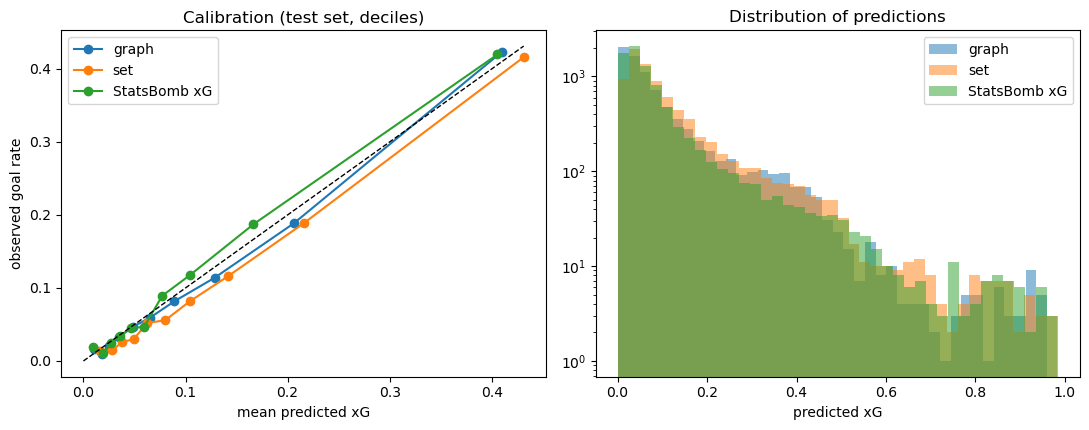

In [19]:
# Calibration plot (deciles of predicted probability)
def calib(y, p, bins=10):
    q = pd.qcut(p, bins, duplicates="drop")
    d = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
    return d["p"].values, d["y"].values

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
mx = 0.0
for k, v in rows.items():
    px_, py_ = calib(y_test, v); mx = max(mx, px_.max(), py_.max())
    ax[0].plot(px_, py_, marker="o", label=k)
ax[0].plot([0, mx], [0, mx], "k--", lw=1); ax[0].set_xlabel("mean predicted xG"); ax[0].set_ylabel("observed goal rate")
ax[0].set_title("Calibration (test set, deciles)"); ax[0].legend()
for k, v in rows.items():
    ax[1].hist(v, bins=40, alpha=0.5, label=k)
ax[1].set_yscale("log"); ax[1].set_xlabel("predicted xG"); ax[1].set_title("Distribution of predictions"); ax[1].legend()
plt.tight_layout(); plt.show()

In [20]:
# Computational cost of each configuration (feeds the 1000x scaling argument)
cost = summarise()[["epoch_time_s_mean", "graphs_per_s_mean", "edges_per_graph_mean", "val_logloss_mean"]]
print(cost.round(3).sort_values("edges_per_graph_mean"))

# save predictions for later notebooks (set model, report figures)
out = pd.DataFrame({"shot_id": SHOT_IDS[IDX["test"]], "match_id": mt, "y": y_test,
                    "p_graph": rows["graph"], "p_set": rows["set"]})
if "StatsBomb xG" in rows:
    out["p_statsbomb"] = rows["StatsBomb xG"]
out.to_csv(PROC / "graph_test_predictions.csv", index=False)
print("saved:", OUT_RESULTS.name, "and graph_test_predictions.csv in", PROC)

                           epoch_time_s_mean  graphs_per_s_mean  \
name                                                              
set (0 rounds)                         0.798          46899.623   
star  R_front=5 R_back=3               2.727          13727.409   
star  R_front=7 R_back=3               2.821          13269.037   
A star                                 3.726          10045.060   
star  R_front=7 R_back=4               2.884          12981.077   
star  7/4, drop outside                1.939          19302.342   
star  R_front=10 R_back=4              3.069          12196.774   
B star+keeper                          4.245           8818.141   
C region full                          5.283           7085.644   
D all-to-all                          25.122           1489.952   
full, 2 rounds                        25.122           1489.952   
readout sum                           12.929           2895.113   
full, 3 rounds                        36.145           1035.58